# Lab 14-14 · AI Accelerators

Companion to [chapter 14-14](../../chapters/14-14-ai-accelerators.md). Part 1 (the Verilog array) runs with `python tools/run_hdl.py 14-14`; this notebook covers Parts 2–4 with the cycle-accurate model in `systolic.py`.

In [1]:
import math, random
import matplotlib.pyplot as plt
import systolic

def product(M, K, N, P, seed=0):
    rng = random.Random(seed)
    A = [[rng.randrange(-9, 10) for _ in range(K)] for _ in range(M)]
    B = [[rng.randrange(-9, 10) for _ in range(N)] for _ in range(K)]
    C, cycles, macs = systolic.run(A, B, P)
    assert C == [[sum(A[i][k] * B[k][j] for k in range(K)) for j in range(N)] for i in range(M)]
    return cycles, macs

## Part 2 · Latency and utilization

**Predict first:** M = 3, K = 5, N = 2 on a 4 × 4 array.

(3, 5, 2) on 4 x 4: 8 cycles; formula 8


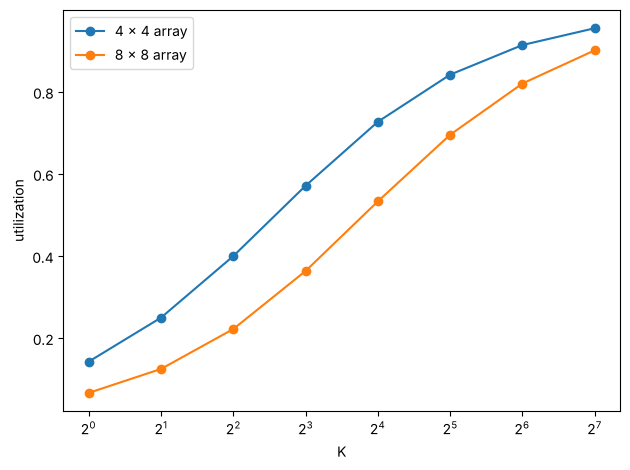

In [2]:
print('(3, 5, 2) on 4 x 4:', product(3, 5, 2, 4)[0], 'cycles; formula', 5 + 3 + 2 - 2)
Ks = [1, 2, 4, 8, 16, 32, 64, 128]
for P in (4, 8):
    u = [systolic.utilization(P, K, P, P, product(P, K, P, P)[0]) for K in Ks]
    plt.plot(Ks, u, marker='o', label=f'{P} x {P} array')
plt.xscale('log', base=2); plt.xlabel('K'); plt.ylabel('utilization'); plt.legend(); plt.tight_layout(); plt.show()

## Part 3 · Tiling

In [3]:
for (M, K, N) in ((1024, 1024, 1024), (2048, 512, 2048), (512, 4096, 512)):
    t = systolic.tiled_cycles(M, K, N, 128)
    ideal = M * K * N / 128**2
    print(f'{M} x {K} x {N}: {t} cycles sequential, ideal {ideal:.0f}, utilization {ideal / t:.3f}')

1024 x 1024 x 1024: 81792 cycles sequential, ideal 65536, utilization 0.801
2048 x 512 x 2048: 196096 cycles sequential, ideal 131072, utilization 0.668
512 x 4096 x 512: 69600 cycles sequential, ideal 65536, utilization 0.942


## Part 4 · Quantization

In [4]:
xs = [math.sin(2 * math.pi * k / 64) for k in range(64)]
for bits in (8, 6, 4):
    q, s, dq = systolic.quantize(xs, bits)
    err = [a - b for a, b in zip(xs, dq)]
    sqnr = 10 * math.log10(sum(a * a for a in xs) / sum(e * e for e in err))
    print(f'{bits} bits: scale {s:.5f}, max error {max(map(abs, err)):.5f}, SQNR {sqnr:.1f} dB (rule {6.02 * bits + 1.76:.1f})')
rng = random.Random(4)
A = [[rng.gauss(0, 1) for _ in range(64)] for _ in range(16)]
B = [[rng.gauss(0, 1) for _ in range(16)] for _ in range(64)]
exact = [[sum(A[i][k] * B[k][j] for k in range(64)) for j in range(16)] for i in range(16)]
for bits in (8, 6, 4):
    qa, sa, _ = systolic.quantize([x for r in A for x in r], bits)
    qb, sb, _ = systolic.quantize([x for r in B for x in r], bits)
    Aq = [qa[16 * 0 + i * 64:(i + 1) * 64] for i in range(16)]
    Bq = [qb[k * 16:(k + 1) * 16] for k in range(64)]
    approx = [[sa * sb * sum(Aq[i][k] * Bq[k][j] for k in range(64)) for j in range(16)] for i in range(16)]
    rel = math.sqrt(sum((approx[i][j] - exact[i][j])**2 for i in range(16) for j in range(16)) / sum(exact[i][j]**2 for i in range(16) for j in range(16)))
    print(f'{bits}-bit integer product: relative error {rel:.4f}')

8 bits: scale 0.00787, max error 0.00369, SQNR 48.7 dB (rule 49.9)
6 bits: scale 0.03226, max error 0.01304, SQNR 39.2 dB (rule 37.9)
4 bits: scale 0.14286, max error 0.06674, SQNR 25.2 dB (rule 25.8)
8-bit integer product: relative error 0.0102
6-bit integer product: relative error 0.0419
4-bit integer product: relative error 0.1941
